# 17 · Continuous and mixed factors: candidate parent sets fitted together

Notebook 14 handled discrete nodes with counts.  Here the next state is
**continuous**, and one node is discrete with a continuous parent.  For every
candidate parent set we fit a structural mechanism `x' = g(pa) + U`, with **all
candidates of a node fitted together** (one stacked network, one mask per
candidate), and then put one **calibrated** set on each factor.

Ground truth (hidden from the learner):

    x' = sin(x) + 0.5 a + U,  U ~ N(0, s(a)^2),  s(0) = 0.1, s(1) = 0.5   (noise depends on a)
    d' = [x + V > 0],         V ~ N(0, 0.5^2)                            (discrete, continuous parent)
    y  : a distractor that nothing depends on

- **NBN API:** `HypothesisSet.fit`, `HypothesisSet.calibrated_sets`, `HypothesisSet.model_for`.
- **Runtime:** under 30 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.structure import HypothesisSet
from nbn.utils.device import resolve_device

device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def simulate(n: int, seed: int) -> dict:
    g = torch.Generator().manual_seed(seed)
    x, y = torch.randn(n, generator=g), torch.randn(n, generator=g)
    a = torch.randint(0, 2, (n,), generator=g).float()
    sd = torch.where(a == 1, 0.5, 0.1)
    x_next = torch.sin(x) + 0.5 * a + sd * torch.randn(n, generator=g)
    d_next = (x + 0.5 * torch.randn(n, generator=g) > 0).float()
    return {"x": x, "y": y, "a": a, "x'": x_next, "d'": d_next}


train, calibration, test = simulate(4000, 0), simulate(1500, 1), simulate(4000, 2)
variables = {"x": ("continuous", 1), "y": ("continuous", 1), "a": ("discrete", 2),
             "x'": ("continuous", 1), "d'": ("discrete", 2)}

device: cpu


## 1. Candidates and one fit per factor

Three candidates per node: the true parents, a superset with the distractor
`y`, and a set that misses a parent.  `fit` trains the candidates of each node
together; every result is a standard NBN mechanism.

In [2]:
hs = HypothesisSet(variables, {
    "x'": [("x", "a"), ("x", "a", "y"), ("a",)],
    "d'": [("x",), ("x", "y"), ("a",)],
})
fitted = hs.fit(train, location="mlp", epochs=150, batch_size=256)
for factor, kind in fitted.kinds.items():
    loss = fitted.train_loss.get(factor)
    print(f"{factor[0]:3s} <- {str(factor[1]):18s} {kind:16s} train loss {'' if loss is None else round(loss, 3)}")

x'  <- ('x', 'a')         mlp              train loss 0.137
x'  <- ('x', 'a', 'y')    mlp              train loss 0.136
x'  <- ('a',)             mlp              train loss 0.568
d'  <- ('a',)             table            train loss 
d'  <- ('x',)             categorical_mlp  train loss 0.326
d'  <- ('x', 'y')         categorical_mlp  train loss 0.323


The true parents and the superset reach the noise level; the candidate
without `x` cannot.  `d' <- (a,)` has only discrete parents, so it is a
count table (PAC sets via `factor_sets`), not a neural factor.

## 2. One calibrated set per factor

Split conformal intervals (CQR) on the held-out calibration rows, at a joint
level of 90%.  The 10% budget is split over **all six** factors of the set
(union bound), so each gets 98.3%; the count table `d' <- (a,)` takes its
share through `factor_sets(delta=0.1)`, and the two together hold at 90%.

In [3]:
cal = hs.calibrated_sets(fitted, calibration, method="cqr", level=0.9)
print("per factor:", round(1 - cal.per_factor, 3), "| guarantees:", set(cal.guarantees.values()))
print("not calibrated here:", cal.skipped)

for parents in hs.candidates["x'"]:
    f = ("x'", parents)
    pa = torch.stack([test[p] for p in parents], -1)
    lo, hi = cal[f].interval(fitted[f], pa)
    inside = (test["x'"] >= lo) & (test["x'"] <= hi)
    width = float((hi - lo).mean())
    print(f"x' <- {str(parents):16s} coverage {inside.float().mean():.3f}   mean width {width:.2f}")

per factor: 0.983 | guarantees: {'marginal'}
not calibrated here: {("d'", ('a',)): 'count-based table: use factor_sets (PAC)'}
x' <- ('x', 'a')       coverage 0.988   mean width 2.31
x' <- ('x', 'a', 'y')  coverage 0.990   mean width 2.36
x' <- ('a',)           coverage 0.988   mean width 3.39


Every candidate reaches its marginal coverage, the wrong one included: its
intervals are just wider.  Coverage alone does not tell the candidates apart;
the width does.

## 3. Marginal is not conditional

The noise of `x'` is small when `a = 0` and large when `a = 1`, but the fitted
noise law is one Gaussian per factor.  The intervals reach their per-factor
level **on average**, over-cover when `a = 0` and under-cover when `a = 1`.  This is what "marginal" means, and why these
sets do not support a per-row worst case in robust planning (Kochenderfer et
al., *Algorithms for Validation*, §12.2.3, p. 340; Ex. 12.7, p. 345).

coverage given a: {0: 1.0, 1: 0.976} | overall: 0.988


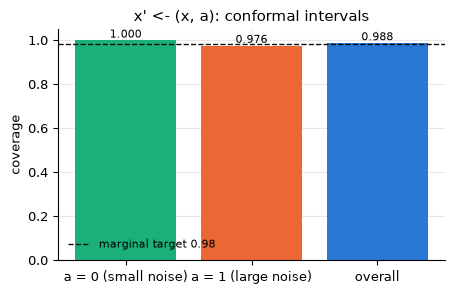

In [4]:
f = ("x'", ("x", "a"))
pa = torch.stack([test["x"], test["a"]], -1)
lo, hi = cal[f].interval(fitted[f], pa)
inside = (test["x'"] >= lo) & (test["x'"] <= hi)
by_a = {int(v): float(inside[test["a"] == v].float().mean()) for v in (0, 1)}
print("coverage given a:", {k: round(v, 3) for k, v in by_a.items()},
      "| overall:", round(float(inside.float().mean()), 3))

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(["a = 0 (small noise)", "a = 1 (large noise)", "overall"],
              [by_a[0], by_a[1], float(inside.float().mean())], color=[AQUA, ORANGE, BLUE])
ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.axhline(1 - cal.per_factor, color=INK, ls="--", lw=1, label=f"marginal target {1 - cal.per_factor:.2f}")
ax.set(ylim=(0, 1.05), ylabel="coverage", title="x' <- (x, a): conformal intervals")
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.show()

## 4. A discrete child with a continuous parent

`d'` gets conformal **sets** of classes.  The best classifier is right about
85% of the time, so a set that must contain the class in 98.3% of rows (the
split level per factor) holds both classes for about half of the rows.  For
this factor on its own at 80% (`conformal_sets` on the factor's model, kept in
`cal.models`), every set is a single class, and coverage (0.85) is above 80%
because the default `score="exclusive"` ties all correct top-class rows at
score 0.  The other scores, and why the default is robust when the
classifier is very confident, are in notebook 13, section 5.

In [5]:
from nbn.scm import conformal_sets

for parents in [("x",), ("x", "y")]:
    f = ("d'", parents)
    pa = torch.stack([test[p] for p in parents], -1)
    for label, sets in ((f"joint, {1 - cal.per_factor:.1%} per factor", cal[f]),
                        ("this factor alone, 80%", conformal_sets(cal.models[f], calibration, "d'", alpha=0.2))):
        member = sets.sets(fitted[f], pa)                 # [N, K] booleans
        covered = member[torch.arange(member.shape[0]), test["d'"].long()]
        print(f"d' <- {str(parents):10s} {label:24s} coverage {covered.float().mean():.3f}   "
              f"mean set size {member.float().sum(-1).mean():.2f}")

d' <- ('x',)     joint, 98.3% per factor  coverage 0.979   mean set size 1.45
d' <- ('x',)     this factor alone, 80%   coverage 0.850   mean set size 1.00
d' <- ('x', 'y') joint, 98.3% per factor  coverage 0.982   mean set size 1.47
d' <- ('x', 'y') this factor alone, 80%   coverage 0.850   mean set size 1.00


## 5. A model for one hypothesis

`model_for` builds a `StructuralCausalModel` with copies of the fitted
mechanisms, ready for queries, sampling and counterfactuals.

In [6]:
model = hs.model_for({"x'": ("x", "a"), "d'": ("x",)}, fitted)
print(type(model).__name__, "nodes:", model.dag.nodes())
samples = model.sample(5)
print({k: [round(v, 2) for v in t.reshape(-1).tolist()] for k, t in samples.items()})

StructuralCausalModel nodes: ['x', "x'", 'a', "d'"]
{'x': [0.69, 0.56, 0.86, -0.15, 0.5], 'a': [0.0, 0.0, 1.0, 1.0, 1.0], "d'": [1, 1, 1, 1, 1], "x'": [0.31, 0.38, 0.61, 0.71, 0.23]}
